# 2018 — GPT: Generative Pre-Training (Decoder-Only Transformers)

**Papers:** Alec Radford et al., *"Improving Language Understanding by Generative Pre-Training"* (GPT, 2018); *"Language Models are Unsupervised Multitask Learners"* (GPT-2, 2019); Brown et al., *"Language Models are Few-Shot Learners"* (GPT-3, 2020).

Take only the **decoder** of the Transformer (causal self-attention, no cross-attention) and train it on one objective, **next-token prediction**:

$$\mathcal L = -\sum_t \log p_\theta(x_t \mid x_{<t})$$

That simple objective, scaled up, is the basis of today's large language models. Changes from 2017 to GPT-2 that we use here:
- **Pre-LayerNorm** (normalise *before* each sub-layer), which is more stable for deep stacks
- **Learned positional embeddings** and **GELU** activations
- **Weight tying** between the input embedding and the output layer

A tiny character-level GPT trained on a ~2 KB corpus. It will mostly memorise; the point is the mechanics.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A small original corpus (written for this repo) so the notebook runs offline.
CORPUS = """In the beginning a neuron was only a switch. It added up its inputs, compared the sum with a threshold, and fired or stayed silent. Logicians showed that networks of such switches could compute anything a machine could compute, but nobody knew how to choose the connections.
The perceptron answered part of that question. It changed its weights a little every time it made a mistake, and if the classes could be split by a straight line, it was guaranteed to find one. Critics then pointed out that a single layer could not even learn exclusive or, and the field grew quiet for many years.
Backpropagation brought it back. By sending errors backwards through the chain rule, a network with hidden layers could learn its own features. Convolutional networks learned to read handwritten digits, and recurrent networks learned to carry information through time. The long short term memory added gates so that gradients could survive across many steps.
Then data grew large and graphics cards grew fast. A deep convolutional network won an image contest by a wide margin, and suddenly every lab wanted deeper models. Residual connections let networks grow to hundreds of layers. Normalization kept the signals steady. Generative models learned to dream new images from noise.
Attention changed everything again. Instead of reading a sentence one word at a time, a transformer lets every word look at every other word at once. Stack enough of these layers, feed them enough text, and they learn grammar, facts, and a surprising amount of reasoning. Scaling the data and the parameters together turned out to be a reliable recipe.
Today the frontier mixes many ideas. Mixtures of experts activate only a few parameters per token. Linear recurrent layers with gated memory handle very long contexts cheaply. Diffusion and flow models paint images, sound, and video. Reinforcement learning with verifiable rewards teaches models to think before they answer. Yet every one of these systems is still built from the same humble part: a weighted sum followed by a simple nonlinearity.
"""
print(f"corpus: {len(CORPUS):,} characters")
chars = sorted(set(CORPUS)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in CORPUS], device=device)
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)

corpus: 2,073 characters


In [3]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d, h, ctx, p):
        super().__init__()
        self.qkv, self.proj, self.h = nn.Linear(d, 3 * d), nn.Linear(d, d), h
        self.drop = nn.Dropout(p)
        self.register_buffer("mask", torch.tril(torch.ones(ctx, ctx, dtype=torch.bool)))
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(D // self.h)
        att = att.masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)
        return self.proj(self.drop(att @ v).transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    def __init__(self, d, h, ctx, p):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = CausalSelfAttention(d, h, ctx, p)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(p))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))          # pre-norm residual blocks
        return x + self.mlp(self.ln2(x))

class GPT(nn.Module):
    def __init__(self, V, d=128, h=4, n=4, ctx=64, p=0.1):
        super().__init__()
        self.ctx = ctx
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.blocks = nn.Sequential(*[Block(d, h, ctx, p) for _ in range(n)])
        self.ln_f, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)
        self.head.weight = self.tok.weight                       # weight tying
        self.apply(lambda m: nn.init.normal_(m.weight, std=0.02) if isinstance(m, (nn.Linear, nn.Embedding)) else None)

    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        return self.head(self.ln_f(self.blocks(x)))

    @torch.no_grad()
    def generate(self, idx, n, temperature=0.8, top_k=10):
        for _ in range(n):
            logits = self(idx[:, -self.ctx:])[:, -1] / temperature
            v, _ = logits.topk(top_k); logits[logits < v[:, -1:]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(logits.softmax(-1), 1)], 1)
        return idx

parameters: 807K


step    0  loss 3.760


step  300  loss 0.721


step  600  loss 0.192


step  900  loss 0.122


step 1200  loss 0.100


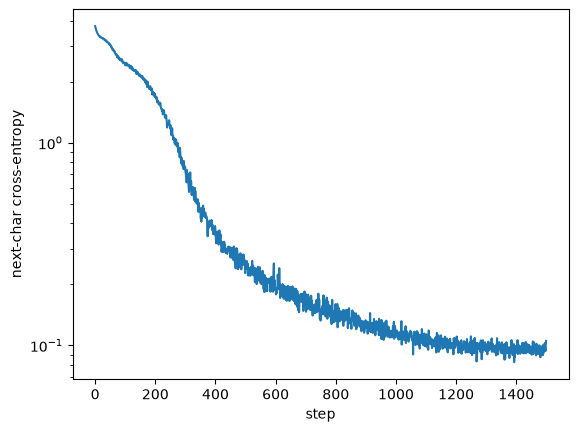

In [4]:
model = GPT(V).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e3:.0f}K")
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.1)
steps, ctx, B = 1500, 64, 32
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps, pct_start=0.1)
losses = []
for step in range(steps):
    model.train()
    ix = torch.randint(0, len(data) - ctx - 1, (B,), device=device)
    x = torch.stack([data[i:i + ctx] for i in ix]); y = torch.stack([data[i + 1:i + ctx + 1] for i in ix])
    loss = F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    losses.append(loss.item())
    if step % 300 == 0: print(f"step {step:4d}  loss {loss.item():.3f}")
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("next-char cross-entropy"); plt.show()

In [5]:
model.eval()
for prompt in ["Attention ", "The perceptron ", "Today the "]:
    out = model.generate(torch.tensor([encode(prompt)], device=device), 200)
    print(repr(decode(out[0].tolist())), "\n")

'Attention changed everything again. Instead of reading a sentence one word at a time, a transformer lets every word look at every other word at once. Stack enough of these layers, feed them enough text, and the' 



'The perceptron answered part of that question. It changed its weights a little every time it made a mistake, and if the classes could be split by a straight line, it was guaranteed to find one. Critics then pointed ' 



'Today the frontier mixes many ideas. Mixtures of experts activate only a few parameters per token. Linear recurrent layers with gated memory handle very long contexts cheaply. Diffusion and flow models paint im' 



## Takeaways
- Decoder-only + next-token prediction + scale = GPT. The architecture above is essentially GPT-2 at toy size.
- The **scaling laws** (Kaplan et al. 2020; Chinchilla, Hoffmann et al. 2022) found that loss falls predictably as a power law in parameters, data and compute.
- See `53_2026_modern_llm_recipe` for how this block evolved (RMSNorm, RoPE, GQA, SwiGLU, ...).